In [2]:

import zipfile
import os

# Localização do arquivo ZIP
arquivo_zip = "/content/online+retail.zip"

# Criar pasta para os dados extraídos
os.makedirs("/content/dados", exist_ok=True)

# Extrair o conteúdo
with zipfile.ZipFile(arquivo_zip, "r") as zip_ref:
    zip_ref.extractall("/content/dados")

print("Arquivo extraído com sucesso!")

# Mostrar os arquivos encontrados
print(os.listdir("/content/dados"))


FileNotFoundError: [Errno 2] No such file or directory: '/content/online+retail.zip'

In [5]:

from google.colab import files

arquivos = files.upload()


Saving online+retail.zip to online+retail.zip


In [6]:

import zipfile
import os
import io

# Identificar o arquivo enviado
nome_arquivo = next(iter(arquivos))

# Criar pasta para os dados
os.makedirs("/content/dados", exist_ok=True)

# Extrair o arquivo ZIP
with zipfile.ZipFile(io.BytesIO(arquivos[nome_arquivo]), "r") as zip_ref:
    zip_ref.extractall("/content/dados")

print("Arquivo extraído com sucesso!")

# Mostrar os arquivos extraídos
print(os.listdir("/content/dados"))


Arquivo extraído com sucesso!
['Online Retail.xlsx']


In [7]:

import pandas as pd

# Abrindo a planilha
caminho = "/content/dados/Online Retail.xlsx"

df = pd.read_excel(caminho)

# Mostrando as primeiras linhas
print("PRIMEIRAS 5 LINHAS:")
display(df.head())


PRIMEIRAS 5 LINHAS:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [8]:

# Quantidade de linhas e colunas
print("Tamanho da base:")
print(df.shape)

# Nomes das colunas
print("\nColunas disponíveis:")
print(df.columns.tolist())

# Informações sobre os dados
print("\nInformações da base:")
df.info()


Tamanho da base:
(541909, 8)

Colunas disponíveis:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Informações da base:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [9]:

# Garantir que a coluna seja reconhecida como data
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

# Identificar a primeira e a última data
print("Primeira compra:")
print(df["InvoiceDate"].min())

print("\nÚltima compra:")
print(df["InvoiceDate"].max())

# Mostrar algumas datas
print("\nExemplos de datas:")
display(df[["InvoiceNo", "InvoiceDate"]].head(10))


Primeira compra:
2010-12-01 08:26:00

Última compra:
2011-12-09 12:50:00

Exemplos de datas:


,InvoiceNo,InvoiceDate
0,536365,2010-12-01 08:26:00
1,536365,2010-12-01 08:26:00
2,536365,2010-12-01 08:26:00
3,536365,2010-12-01 08:26:00
4,536365,2010-12-01 08:26:00
5,536365,2010-12-01 08:26:00
6,536365,2010-12-01 08:26:00
7,536366,2010-12-01 08:28:00
8,536366,2010-12-01 08:28:00
9,536367,2010-12-01 08:34:00


In [10]:
print("PRIMEIRA COMPRA:")
print(df["InvoiceDate"].min())

print("\nÚLTIMA COMPRA:")
print(df["InvoiceDate"].max())

print("\nQUANTIDADE DE DADOS AUSENTES:")
print(df.isnull().sum())

print("\nQUANTIDADE DE PAÍSES:")
print(df["Country"].nunique())

print("\nPAÍSES COM MAIS REGISTROS:")
display(df["Country"].value_counts().head(10))

PRIMEIRA COMPRA:
2010-12-01 08:26:00

ÚLTIMA COMPRA:
2011-12-09 12:50:00

QUANTIDADE DE DADOS AUSENTES:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

QUANTIDADE DE PAÍSES:
38

PAÍSES COM MAIS REGISTROS:


,count
Country,
United Kingdom,495478
Germany,9495
France,8557
EIRE,8196
Spain,2533
Netherlands,2371
Belgium,2069
Switzerland,2002
Portugal,1519


In [11]:
# Verificar registros duplicados

duplicados = df.duplicated().sum()

print("Quantidade de registros duplicados:", duplicados)

Quantidade de registros duplicados: 5268


In [12]:
# Verificar quantidades negativas ou zeradas

print("Quantidade de vendas com quantidade negativa:")
print((df["Quantity"] < 0).sum())

print("\nQuantidade de vendas com quantidade igual a zero:")
print((df["Quantity"] == 0).sum())

print("\nQuantidade de preços negativos ou iguais a zero:")
print((df["UnitPrice"] <= 0).sum())

Quantidade de vendas com quantidade negativa:
10624

Quantidade de vendas com quantidade igual a zero:
0

Quantidade de preços negativos ou iguais a zero:
2517


In [13]:
# Criar uma cópia para preparação dos dados

df_tratado = df.copy()

print("Cópia criada com sucesso!")
print("Tamanho da base:", df_tratado.shape)

Cópia criada com sucesso!
Tamanho da base: (541909, 8)


In [14]:
# Criar uma cópia para preparação dos dados

df_tratado = df.copy()

print("Cópia criada com sucesso!")
print("Tamanho da base:", df_tratado.shape)

Cópia criada com sucesso!
Tamanho da base: (541909, 8)


In [15]:
# Verificar registros duplicados

duplicados = df_tratado.duplicated().sum()

print("Quantidade de registros duplicados:", duplicados)

Quantidade de registros duplicados: 5268


In [16]:
print("Quantidade de vendas com quantidade negativa:")
print((df_tratado["Quantity"] < 0).sum())

print("\nQuantidade de vendas com quantidade igual a zero:")
print((df_tratado["Quantity"] == 0).sum())

print("\nQuantidade de preços negativos ou iguais a zero:")
print((df_tratado["UnitPrice"] <= 0).sum())

Quantidade de vendas com quantidade negativa:
10624

Quantidade de vendas com quantidade igual a zero:
0

Quantidade de preços negativos ou iguais a zero:
2517


In [17]:
display(df_tratado[df_tratado.duplicated(keep=False)].head(10))

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
548,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom


In [18]:
display(df_tratado[df_tratado["Quantity"] < 0].head(10))

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom


In [19]:
display(df_tratado[df_tratado["UnitPrice"] <= 0].head(10))

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom


In [20]:
# Guardar a quantidade inicial de registros
total_inicial = len(df_tratado)

# 1. Remover registros duplicados
duplicados_removidos = df_tratado.duplicated().sum()
df_tratado = df_tratado.drop_duplicates()

# 2. Identificar registros sem quantidade ou preço válido
registros_invalidos = (
    (df_tratado["Quantity"] <= 0) |
    (df_tratado["UnitPrice"] <= 0)
).sum()

# 3. Manter somente vendas com quantidade e preço positivos
df_tratado = df_tratado[
    (df_tratado["Quantity"] > 0) &
    (df_tratado["UnitPrice"] > 0)
].copy()

# Mostrar os resultados
print("Registros iniciais:", total_inicial)
print("Duplicados removidos:", duplicados_removidos)
print("Registros com quantidade ou preço inválido removidos:", registros_invalidos)
print("Registros restantes:", len(df_tratado))
print("Novo tamanho da base:", df_tratado.shape)

Registros iniciais: 541909
Duplicados removidos: 5268
Registros com quantidade ou preço inválido removidos: 11763
Registros restantes: 524878
Novo tamanho da base: (524878, 8)


In [21]:
# Calcular o valor total de cada registro de venda

df_tratado["TotalPrice"] = (
    df_tratado["Quantity"] * df_tratado["UnitPrice"]
)

# Visualizar os resultados
display(
    df_tratado[
        ["InvoiceNo", "Description", "Quantity", "UnitPrice", "TotalPrice"]
    ].head(10)
)

,InvoiceNo,Description,Quantity,UnitPrice,TotalPrice
0,536365,WHITE HANGING HEART T-LIGHT HOLDER,6,2.55,15.30
1,536365,WHITE METAL LANTERN,6,3.39,20.34
2,536365,CREAM CUPID HEARTS COAT HANGER,8,2.75,22.00
3,536365,KNITTED UNION FLAG HOT WATER BOTTLE,6,3.39,20.34
4,536365,RED WOOLLY HOTTIE WHITE HEART.,6,3.39,20.34
5,536365,SET 7 BABUSHKA NESTING BOXES,2,7.65,15.30
6,536365,GLASS STAR FROSTED T-LIGHT HOLDER,6,4.25,25.50
7,536366,HAND WARMER UNION JACK,6,1.85,11.10
8,536366,HAND WARMER RED POLKA DOT,6,1.85,11.10
9,536367,ASSORTED COLOUR BIRD ORNAMENT,32,1.69,54.08


In [22]:
faturamento_total = df_tratado["TotalPrice"].sum()

print("Faturamento total:", faturamento_total)

Faturamento total: 10642110.804000001


In [23]:
# Identificar os 10 produtos com maior faturamento

top_produtos = (
    df_tratado.groupby("Description")["TotalPrice"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("TOP 10 PRODUTOS COM MAIOR FATURAMENTO:")
display(top_produtos)

TOP 10 PRODUTOS COM MAIOR FATURAMENTO:


,TotalPrice
Description,
DOTCOM POSTAGE,206248.77
REGENCY CAKESTAND 3 TIER,174156.54
"PAPER CRAFT , LITTLE BIRDIE",168469.60
WHITE HANGING HEART T-LIGHT HOLDER,106236.72
PARTY BUNTING,99445.23
JUMBO BAG RED RETROSPOT,94159.81
MEDIUM CERAMIC TOP STORAGE JAR,81700.92
POSTAGE,78101.88
Manual,77752.82


In [24]:
# Identificar os 10 países com maior faturamento

top_paises = (
    df_tratado.groupby("Country")["TotalPrice"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("TOP 10 PAÍSES COM MAIOR FATURAMENTO:")
display(top_paises)

TOP 10 PAÍSES COM MAIOR FATURAMENTO:


,TotalPrice
Country,
United Kingdom,9001744.094
Netherlands,285446.340
EIRE,283140.520
Germany,228678.400
France,209625.370
Australia,138453.810
Spain,61558.560
Switzerland,57067.600
Belgium,41196.340


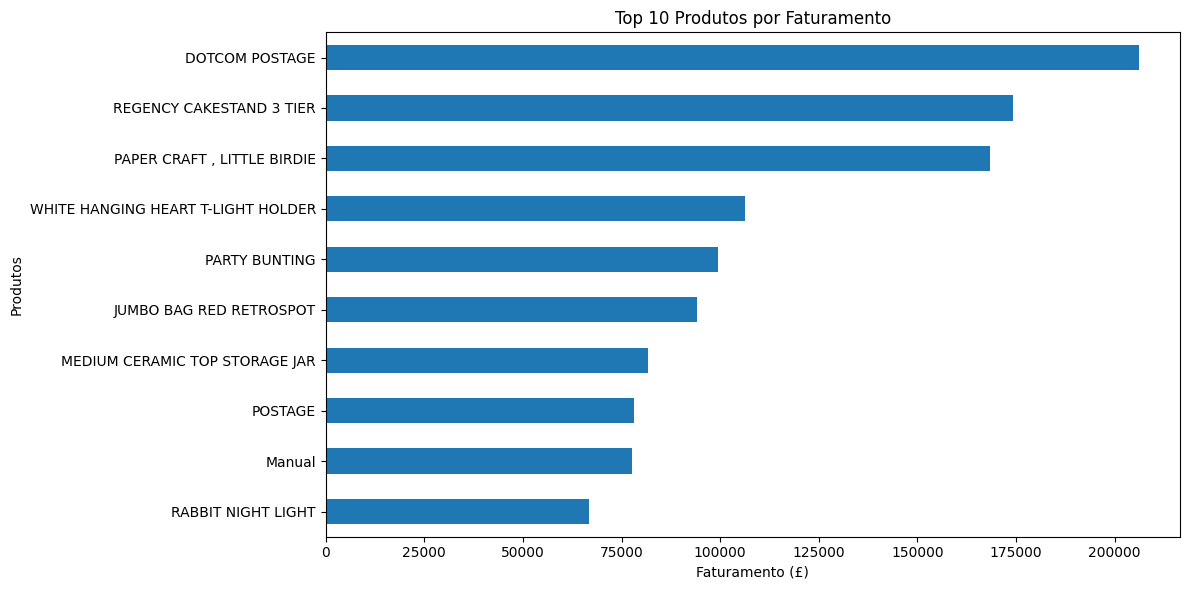

In [25]:
import matplotlib.pyplot as plt

# Gráfico dos 10 produtos com maior faturamento
plt.figure(figsize=(12, 6))

top_produtos.sort_values().plot(kind="barh")

plt.title("Top 10 Produtos por Faturamento")
plt.xlabel("Faturamento (£)")
plt.ylabel("Produtos")
plt.tight_layout()
plt.show()

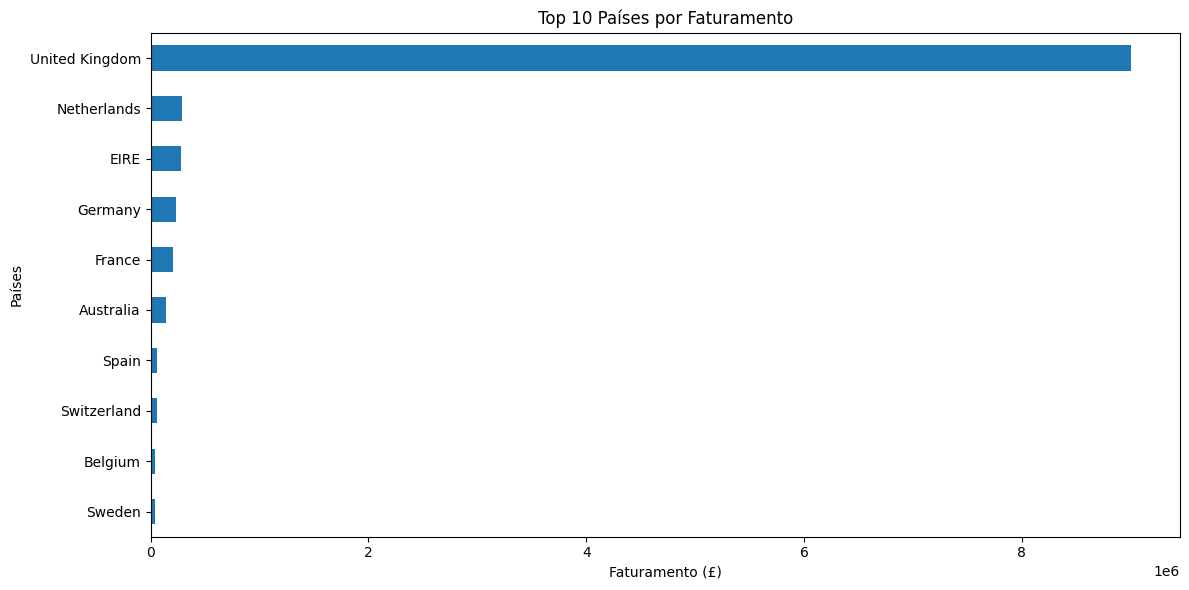

In [26]:
# Gráfico dos 10 países com maior faturamento
plt.figure(figsize=(12, 6))

top_paises.sort_values().plot(kind="barh")

plt.title("Top 10 Países por Faturamento")
plt.xlabel("Faturamento (£)")
plt.ylabel("Países")
plt.tight_layout()
plt.show()

In [27]:
# Criar uma coluna com o mês e o ano da compra

df_tratado["AnoMes"] = df_tratado["InvoiceDate"].dt.to_period("M")

# Somar o faturamento de cada mês

vendas_mensais = (
    df_tratado.groupby("AnoMes")["TotalPrice"]
    .sum()
)

print("FATURAMENTO POR MÊS:")
display(vendas_mensais)

FATURAMENTO POR MÊS:


,TotalPrice
AnoMes,
2010-12,821452.730
2011-01,689811.610
2011-02,522545.560
2011-03,716215.260
2011-04,536968.491
2011-05,769296.610
2011-06,760547.010
2011-07,718076.121
2011-08,757841.380


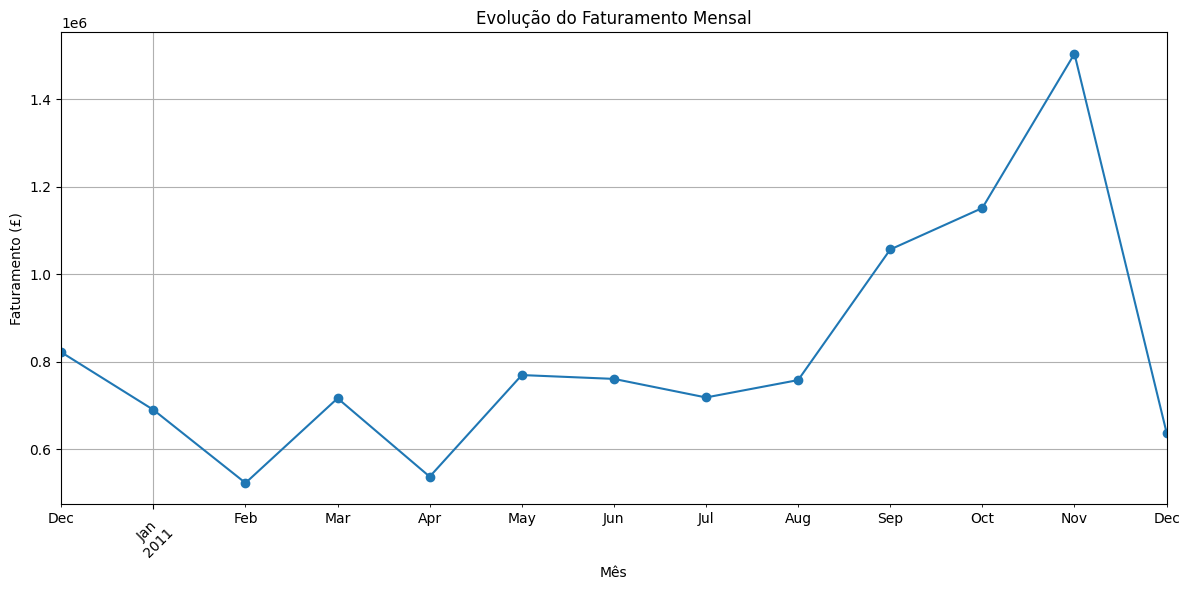

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

vendas_mensais.plot(kind="line", marker="o")

plt.title("Evolução do Faturamento Mensal")
plt.xlabel("Mês")
plt.ylabel("Faturamento (£)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [29]:
melhor_mes = vendas_mensais.idxmax()
maior_faturamento = vendas_mensais.max()

print("Mês com maior faturamento:", melhor_mes)
print("Maior faturamento: £", round(maior_faturamento, 2))

Mês com maior faturamento: 2011-11
Maior faturamento: £ 1503866.78


In [30]:
# Contar a quantidade de notas fiscais por país

vendas_por_pais = (
    df_tratado.groupby("Country")["InvoiceNo"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
)

print("TOP 10 PAÍSES POR QUANTIDADE DE COMPRAS:")
display(vendas_por_pais)

TOP 10 PAÍSES POR QUANTIDADE DE COMPRAS:


,InvoiceNo
Country,
United Kingdom,18019
Germany,457
France,392
EIRE,288
Belgium,98
Netherlands,94
Spain,90
Portugal,58
Australia,57


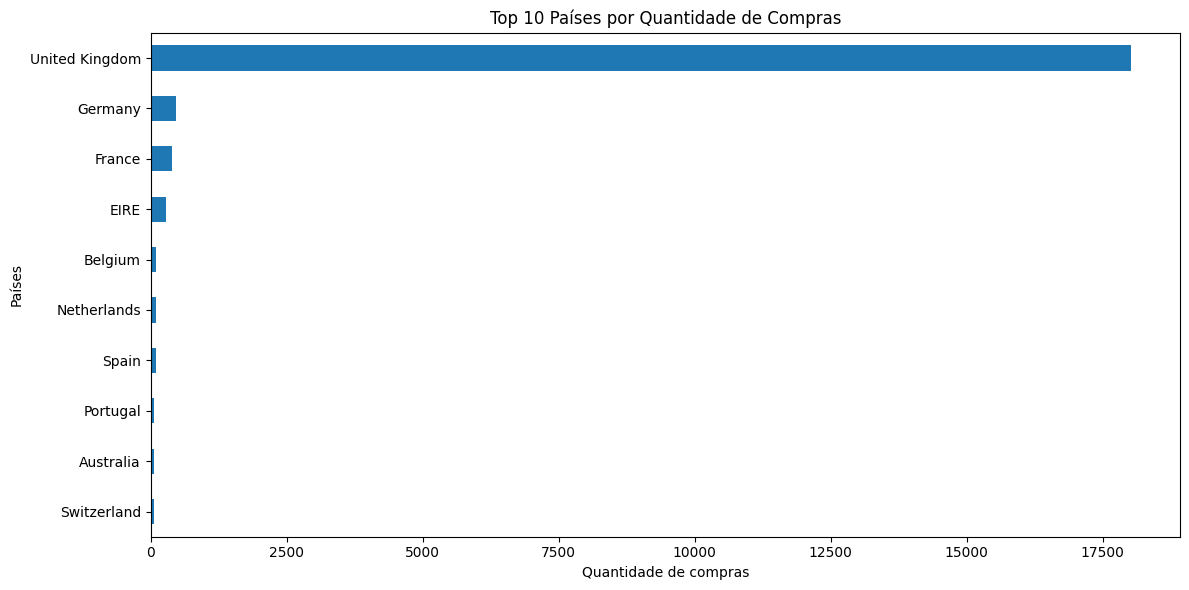

In [31]:
# Criar gráfico

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

vendas_por_pais.sort_values().plot(kind="barh")

plt.title("Top 10 Países por Quantidade de Compras")
plt.xlabel("Quantidade de compras")
plt.ylabel("Países")
plt.tight_layout()
plt.show()

In [32]:
# Contar as notas fiscais distintas por mês
compras_mensais = (
    df_tratado.groupby("AnoMes")["InvoiceNo"]
    .nunique()
)

display(compras_mensais)


,InvoiceNo
AnoMes,
2010-12,1559
2011-01,1086
2011-02,1100
2011-03,1454
2011-04,1246
2011-05,1681
2011-06,1533
2011-07,1475
2011-08,1361


In [33]:
# Contar a quantidade de clientes únicos
total_clientes = df_tratado["CustomerID"].nunique()

print("Quantidade de clientes únicos:", total_clientes)

Quantidade de clientes únicos: 4338


In [34]:
top_clientes = (
    df_tratado.groupby("CustomerID")["TotalPrice"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("TOP 10 CLIENTES POR VALOR DE COMPRAS:")
display(top_clientes)

TOP 10 CLIENTES POR VALOR DE COMPRAS:


,TotalPrice
CustomerID,
14646.0,280206.02
18102.0,259657.30
17450.0,194390.79
16446.0,168472.50
14911.0,143711.17
12415.0,124914.53
14156.0,117210.08
17511.0,91062.38
16029.0,80850.84


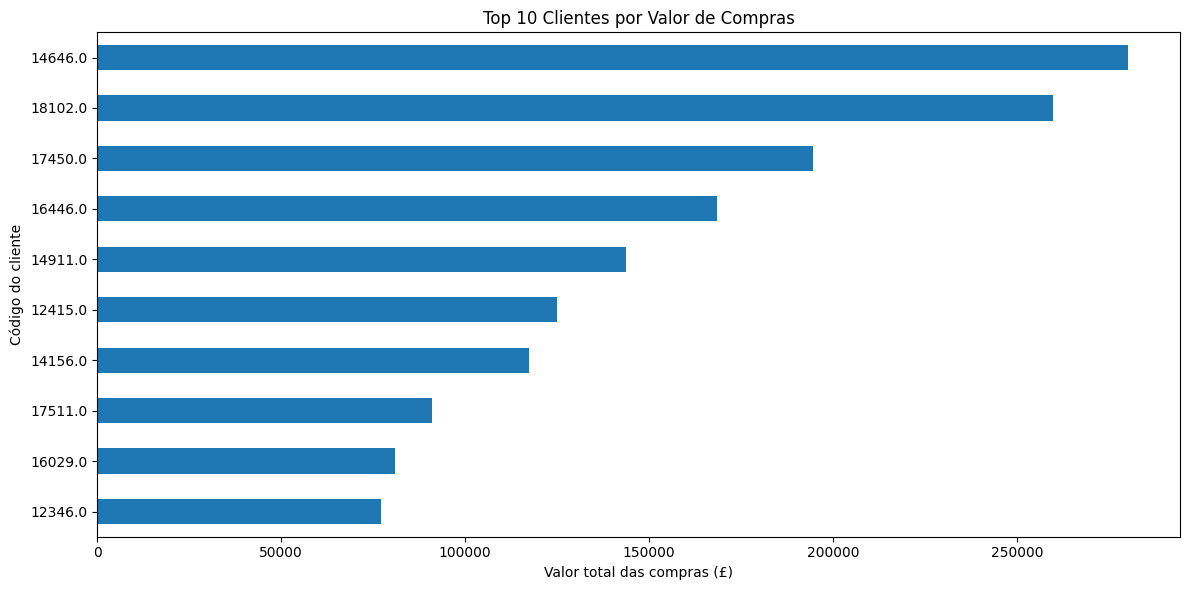

In [35]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

top_clientes.sort_values().plot(kind="barh")

plt.title("Top 10 Clientes por Valor de Compras")
plt.xlabel("Valor total das compras (£)")
plt.ylabel("Código do cliente")

plt.tight_layout()
plt.show()

In [36]:
# Verificar dados ausentes na base tratada
dados_ausentes = df_tratado.isnull().sum()

print("QUANTIDADE DE DADOS AUSENTES POR COLUNA:")
display(dados_ausentes)

QUANTIDADE DE DADOS AUSENTES POR COLUNA:


,0
InvoiceNo,0
StockCode,0
Description,0
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,132186
Country,0
TotalPrice,0
AnoMes,0


In [37]:
# Calcular o percentual de clientes sem identificação
percentual_ausente = (
    df_tratado["CustomerID"].isnull().mean() * 100
)

print(f"Percentual de CustomerID ausentes: {percentual_ausente:.2f}%")

Percentual de CustomerID ausentes: 25.18%


In [38]:
print("Quantidade de registros:", len(df_tratado))
print("Quantidade de colunas:", len(df_tratado.columns))
print("Período inicial:", df_tratado["InvoiceDate"].min())
print("Período final:", df_tratado["InvoiceDate"].max())

Quantidade de registros: 524878
Quantidade de colunas: 10
Período inicial: 2010-12-01 08:26:00
Período final: 2011-12-09 12:50:00
